In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Data.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (51783, 8)

Column names:
['user_id', 'recording_url', 'whisper_text', 'user_text', 'is_edited', 'duration', 'time_taken_by_user', 'segment_character_per_second']


,user_id,recording_url,whisper_text,user_text,is_edited,duration,time_taken_by_user,segment_character_per_second
0,71275781,https://storage.googleapis.com/joshtalks-data-...,इन जॉब में तो बहुत पैसे कमा है आपने,इन जॉब में तो बहुत पैसे कमा है आपने,No,2.94,15.00,9.18
1,71275800,https://storage.googleapis.com/joshtalks-data-...,NaN,हूं,Yes,0.96,14.26,3.13
2,71275813,https://storage.googleapis.com/joshtalks-data-...,तो उसमें एक मन एक मंत की सैल्वी उसमें आठ लिया...,तो उसमें एक मन एक मंत की सैलरी उसमें आठ लिया ...,Yes,4.83,20.85,7.87
3,71275842,https://storage.googleapis.com/joshtalks-data-...,NaN,हूं,Yes,0.45,8.46,6.67
4,71275856,https://storage.googleapis.com/joshtalks-data-...,NaN,हूं,Yes,0.27,11.65,11.11


In [44]:
missing= pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean()*100).round(2)
})
display(missing)

print("Duplicate rows:", df.duplicated().sum())
print("Unique users:", df["user_id"].nunique())

display(df.describe().T)


,Missing Count,Missing %
user_id,0,0.00
recording_url,0,0.00
whisper_text,23102,44.61
user_text,0,0.00
is_edited,0,0.00
duration,0,0.00
time_taken_by_user,180,0.35
segment_character_per_second,0,0.00


Duplicate rows: 0
Unique users: 48875


,count,mean,std,min,25%,50%,75%,max
user_id,51783.0,6.733525e+07,1.678710e+07,222099.00,71423015.50,72106392.00,7.304878e+07,75326070.00
duration,51783.0,5.476843e+00,4.751795e+00,0.03,0.90,4.00,1.008000e+01,19.00
time_taken_by_user,51603.0,1.595876e+02,1.390559e+03,0.00,4.68,12.00,4.536500e+01,72813.27
segment_character_per_second,51783.0,1.200151e+01,1.073570e+01,0.00,6.90,10.37,1.292000e+01,233.33


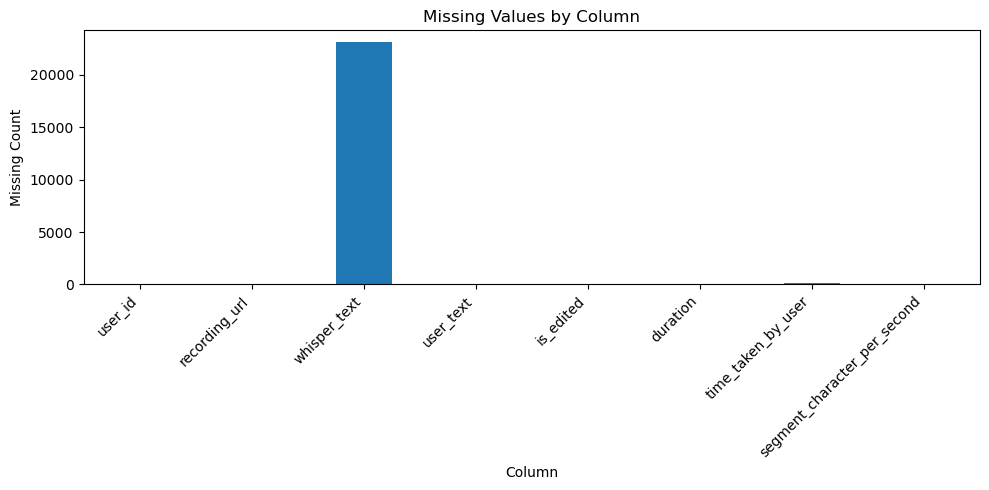

In [45]:
missing["Missing Count"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("missing_values.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
valid = (
    df["duration"].notna()
    & df["time_taken_by_user"].notna()
    & (df["duration"] > 0)
    & (df["time_taken_by_user"] >= 0)
)
analysis_df = df.loc[valid].copy()

analysis_df["Time_ratio"] = (
    analysis_df["time_taken_by_user"]
    / analysis_df["duration"]
)



print("Valid tasks:", len(analysis_df))
print(
    "Tasks with time ratio < 1:",
    (analysis_df["Time_ratio"] < 1).sum()
)
print(
    "Percentage:",
    round((analysis_df["Time_ratio"] < 1).mean() * 100, 2),
    "%"
)

print("\nTime ratio percentiles:")
display(
    analysis_df["Time_ratio"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

Valid tasks: 51603
Tasks with time ratio < 1: 5991
Percentage: 11.61 %

Time ratio percentiles:


0.50      6.28
0.75     13.59
0.90     27.27
0.95     50.75
0.99    685.31
Name: Time_ratio, dtype: float64

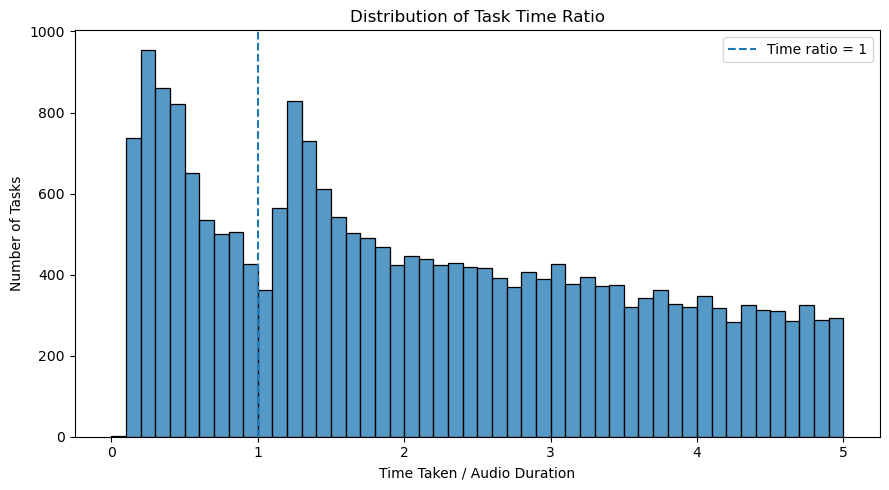

In [17]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=analysis_df[analysis_df["Time_ratio"] <= 5],
    x="Time_ratio",
    bins=50
)

plt.axvline(
    1,
    linestyle="--",
    label="Time ratio = 1"
)

plt.title("Distribution of Task Time Ratio")
plt.xlabel("Time Taken / Audio Duration")
plt.ylabel("Number of Tasks")
plt.legend()
plt.tight_layout()
plt.show()


In [19]:

thresholds = [0.5, 0.75, 1.0]

results = []

for i in thresholds:
    count = (analysis_df["Time_ratio"] < i).sum()

    results.append({
        "Threshold": i,
        "Flagged Tasks": count,
        "Percentage": round(
            count / len(analysis_df) * 100, 2
        )
    })

threshold_table = pd.DataFrame(results)
display(threshold_table)



print("Time ratio percentiles:")
display(
    analysis_df["Time_ratio"].quantile([0.50, 0.75, 0.90, 0.95, 0.99]).to_frame().round(2)
)

,Threshold,Flagged Tasks,Percentage
0,0.50,3375,6.54
1,0.75,4834,9.37
2,1.00,5991,11.61


Time ratio percentiles:


,Time_ratio
0.50,6.28
0.75,13.59
0.90,27.27
0.95,50.75
0.99,685.31


In [20]:
print("Low time + no edit behaviour")

Low time + no edit behaviour


In [23]:
analysis_df["edit_status"] = analysis_df["is_edited"] .astype(str).str.strip().str.lower()

analysis_df["low_time_ratio"] = analysis_df["Time_ratio"] < 0.5

analysis_df["no_edit"] = (analysis_df["edit_status"] == "no")

summary = (
    analysis_df.groupby("low_time_ratio").agg(
                                                total_tasks=("user_id", "size"),
                                                no_edit_tasks=("no_edit", "sum"),
                                                no_edit_rate=("no_edit", "mean")
                                            )
)

summary["no_edit_rate"] = (summary["no_edit_rate"] * 100).round(2)

summary.index = [
    "Time ratio >= 0.5",
    "Time ratio < 0.5"
]

display(summary)



,total_tasks,no_edit_tasks,no_edit_rate
Time ratio >= 0.5,48228,6069,12.58
Time ratio < 0.5,3375,2507,74.28


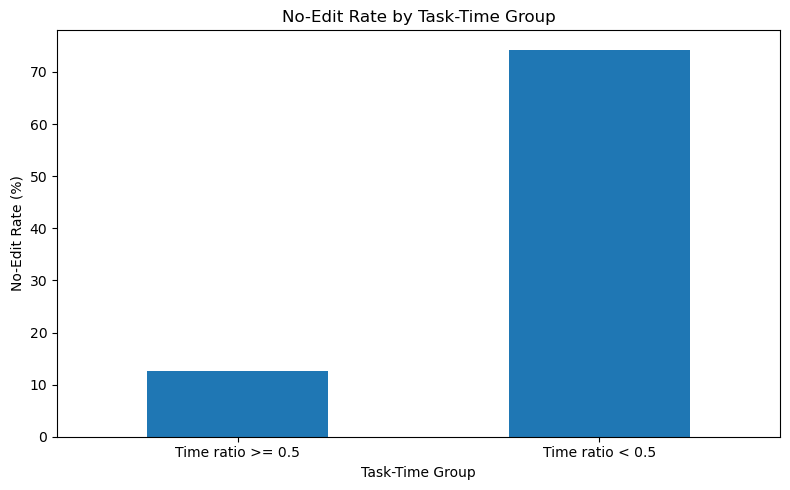

In [46]:
summary = (
    analysis_df
    .groupby("low_time_ratio")["no_edit"]
    .mean() * 100
)

summary.index = ["Time ratio >= 0.5", "Time ratio < 0.5"]

summary.plot(kind="bar", figsize=(8, 5))

plt.title("No-Edit Rate by Task-Time Group")
plt.ylabel("No-Edit Rate (%)")
plt.xlabel("Task-Time Group")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("no_edit_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
print("Characters per second (CPS)")

Characters per second (CPS)


In [25]:
cps_summary = analysis_df.groupby("low_time_ratio")["segment_character_per_second"].agg(
                                                                                        ["count", "median", "mean"]
                                                                                    ).round(2)


cps_summary.index = [
    "Time ratio >= 0.5",
    "Time ratio < 0.5"
]

display(cps_summary)

print("CPS percentiles:")

display(
    analysis_df["segment_character_per_second"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

,count,median,mean
Time ratio >= 0.5,48228,10.45,12.29
Time ratio < 0.5,3375,9.38,7.99


CPS percentiles:


0.50    10.36
0.75    12.92
0.90    17.95
0.95    36.64
0.99    58.33
Name: segment_character_per_second, dtype: float64

In [26]:
print("Verify whether the edit labels are reliable")

Verify whether the edit labels are reliable


In [28]:
text_df = df.dropna(
    subset=["whisper_text", "user_text", "is_edited"]
).copy()

def normalize_text(text):
    return " ".join(str(text).lower().split())

text_df["whisper_normalized"] = text_df["whisper_text"].map(normalize_text)

text_df["user_normalized"] = text_df["user_text"].map(normalize_text)

text_df["text_changed"] = (
    text_df["whisper_normalized"]
    != text_df["user_normalized"]
)

text_df["edit_status"] = (
    text_df["is_edited"].astype(str).str.strip().str.lower()
)

text_df["label_says_edited"] = (text_df["edit_status"] == "yes")

print("Rows with both texts:", len(text_df))

print("\nText changed according to comparison:")
display(text_df["text_changed"].value_counts())

print("\nEdit-label vs text-comparison:")
display(
    pd.crosstab(
        text_df["label_says_edited"],
        text_df["text_changed"],
        rownames=["is_edited says Yes"],
        colnames=["Normalized texts differ"]
    )
)

Rows with both texts: 28681

Text changed according to comparison:


text_changed
True     19542
False     9139
Name: count, dtype: int64


Edit-label vs text-comparison:


Normalized texts differ,False,True
is_edited says Yes,,
False,8591,0
True,548,19542


In [29]:
print("Inspect rows marked edited, but normalized texts match")

Inspect rows marked edited, but normalized texts match


In [30]:
check = text_df[text_df["label_says_edited"]& (~text_df["text_changed"])]

display(
    check[["whisper_text", "user_text", "is_edited"]].head(10)
)

,whisper_text,user_text,is_edited
237,बस ठीक सपनों का इवेंट,बस ठीक सपनों का इवेंट,Yes
291,हम भी जाते हैं कभी-कभी तो फोटो सूट कर लेते है...,हम भी जाते हैं कभी-कभी तो फोटो सूट कर लेते हैं...,Yes
296,ताकि जाकर वहाँ पर गोलगप्पे खा सकते तो वो चीज़...,ताकि जाकर वहाँ पर गोलगप्पे खा सकते तो वो चीज़े...,Yes
307,यह तो चाय वगैरह यह पसंद जाएं बच्चपन के पसंद ख...,यह तो चाय वगैरह यह पसंद जाएं बच्चपन के पसंद खा...,Yes
309,अच्छा आप ऐसे टीम बना के खेली हैं या सिर्फ एक ...,अच्छा आप ऐसे टीम बना के खेली हैं या सिर्फ एक य...,Yes
313,"बच्चपन का कौन सा सपना अब भी हल्की जमगी, अगर ह...","\nबच्चपन का कौन सा सपना अब भी हल्की जमगी, अगर...",Yes
315,"प्राइबी करते थे, हाँ जी, तो कहीं न गईं, आपके ...","प्राइबी करते थे, हाँ जी, तो कहीं न गईं, आपके ल...",Yes
446,कभी ऐसा हुआ है कि आपने बिना सूच से समझे शौपिं...,कभी ऐसा हुआ है कि आपने बिना सूच से समझे शौपिंग...,Yes
461,"एक बार वैसे भी मेरी दीदी घर पे मंचुरेन बनाई, ...","एक बार वैसे भी मेरी दीदी घर पे मंचुरेन बनाई, म...",Yes
465,और बाकी इसके साथ साथ अगर हम अपना फूड फूड को ब...,और बाकी इसके साथ साथ अगर हम अपना फूड फूड को बै...,Yes


In [31]:
print("Differentiating ormatting change aur actual text change ")

Differentiating ormatting change aur actual text change 


In [35]:
check["raw_whisper"] = check["whisper_text"].astype(str)
check["raw_user"] = check["user_text"].astype(str)
check["same_after_strip"] = (
    check["raw_whisper"].str.strip()== check["raw_user"].str.strip()
)
for i, j in check.head(10).iterrows():
    print(f"\nRow index: {i}")
    print("Whisper:", repr(j["raw_whisper"]))
    print("User:   ", repr(j["raw_user"]))
    print("Same after stripping spaces:",
          j["same_after_strip"])


Row index: 237
Whisper: ' बस ठीक सपनों का इवेंट'
User:    'बस ठीक सपनों का इवेंट'
Same after stripping spaces: True

Row index: 291
Whisper: ' हम भी जाते हैं कभी-कभी तो फोटो सूट कर लेते हैं हम एक अपना अनुभव सेयर करते हैं हम एक बार पटना से बघतियारपुर ट्रेवल कर रहे थे तो उस रूट में एक धावा है तो धावा वह लगभग फोरेस्टर धावा है'
User:    'हम भी जाते हैं कभी-कभी तो फोटो सूट कर लेते हैं हम एक अपना अनुभव सेयर करते हैं हम एक बार पटना से बघतियारपुर ट्रेवल कर रहे थे तो उस रूट में एक धावा है तो धावा वह लगभग फोरेस्टर धावा है'
Same after stripping spaces: True

Row index: 296
Whisper: ' ताकि जाकर वहाँ पर गोलगप्पे खा सकते तो वो चीज़े स्पेशल थी हमारे लिए'
User:    'ताकि जाकर वहाँ पर गोलगप्पे खा सकते तो वो चीज़े स्पेशल थी हमारे लिए'
Same after stripping spaces: True

Row index: 307
Whisper: ' यह तो चाय वगैरह यह पसंद जाएं बच्चपन के पसंद खानों के याद करना और इसमें यह भी लगा है परिवार के पुराने पकवानों की बात करना'
User:    'यह तो चाय वगैरह यह पसंद जाएं बच्चपन के पसंद खानों के याद करना और इसमें यह भी लगा

C:\Users\manda\AppData\Local\Temp\ipykernel_21196\3810198183.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  check["raw_whisper"] = check["whisper_text"].astype(str)
C:\Users\manda\AppData\Local\Temp\ipykernel_21196\3810198183.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  check["raw_user"] = check["user_text"].astype(str)
C:\Users\manda\AppData\Local\Temp\ipykernel_21196\3810198183.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_

In [36]:
print("Validating all the 548 rows")

Validating all the 548 rows


In [37]:
print("Total rows to inspect:", len(check))

print(
    "Same after removing outer spaces:",check["same_after_strip"].sum()
)

print(
    "Still different after stripping:",(~check["same_after_strip"]).sum()
)

Total rows to inspect: 548
Same after removing outer spaces: 525
Still different after stripping: 23


In [38]:
print("Inspecting 23 rows")


Inspecting 23 rows


In [40]:
remaining = check[~check["same_after_strip"]]

for i, j in remaining.head(10).iterrows():
    print(f"\nj: {i}")
    print("Whisper:", repr(j["whisper_text"]))
    print("User:   ", repr(j["user_text"]))


j: 2223
Whisper: ' जी जी'
User:    ' जी  जी'

j: 2552
Whisper: ' वो तो बिल्कुल बहुत अच्छा होता है एटमोस्फियर जी जी बिल्कुल'
User:    ' वो तो बिल्कुल बहुत अच्छा होता है एटमोस्फियर जी  जी बिल्कुल'

j: 4332
Whisper: ' कितने दिनों का नौ दिन का नौ दिन का मतलब जैसे हम लोग इधर नवरात्री होता उस तरीके से'
User:    ' कितने दिनों का नौ दिन का नौ दिन का मतलब जैसे हम लोग इधर  नवरात्री होता उस तरीके से'

j: 22385
Whisper: ' अपना दिमाग लगा के वो चीज बना लेते थे'
User:    ' अपना दिमाग लगा  के वो चीज बना लेते थे'

j: 25221
Whisper: ' जी अभी आ रही है'
User:    ' जी अभी आ रही  है '

j: 30047
Whisper: ' प्राउटली कहते हैं कि हाँ तुम इसी चीज में डिग्री करना आगे भी इसी का पढ़ाए करना क्योंकि बच्चे खुद आके मेरे पेरेंस को बोलते कि दीदी कहां है, दीदी कहां है, दीदी से पढ़ना है, दीदी बहुत अच्छा पढ़ाती है, तो उन्हें खुद अब �'
User:    ' प्राउटली कहते हैं कि हाँ तुम इसी चीज में डिग्री करना आगे भी इसी का पढ़ाए करना क्योंकि बच्चे खुद आके मेरे पेरेंस को बोलते कि दीदी कहां है, दीदी कहां है, दीदी से पढ़ना है, दीदी बहुत 

In [41]:
print("final validation")

final validation


In [42]:
import re

def normalize_whitespace(text):
    text = str(text)
    text = text.strip()
    text = " ".join(text.split())
    return text

remaining["same_after_whitespace_normalization"] = (
    remaining["whisper_text"].map(normalize_whitespace)
    == remaining["user_text"].map(normalize_whitespace)
)

print(
    "Same after whitespace normalization:",
    remaining["same_after_whitespace_normalization"].sum()
)

print(
    "Still different:",
    (~remaining["same_after_whitespace_normalization"]).sum()
)

Same after whitespace normalization: 23
Still different: 0


C:\Users\manda\AppData\Local\Temp\ipykernel_21196\53363636.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  remaining["same_after_whitespace_normalization"] = (



# Q2: Identifying Low-Quality Transcription Work

## Data Analysis and Findings

### 1. Introduction

In this analysis, I have done the EDA part and explored the given transcription dataset to understand how we can identify tasks that may have quality issues.

I started by checking the dataset, missing values, and the available columns. After that, I looked at task completion time, whether users edited the Whisper-generated text, and how quickly text was submitted.
My main aim was to find patterns that could help us identify tasks that need further review. I have also considered cases where a task may look suspicious but could actually be completely fine.
The analysis is based on the available data, so the findings should be treated as possible warning signs rather than proof of poor transcription quality.



### 2. Understanding the Dataset

The dataset contains 51,783 tasks and 48,875 unique users. It includes information such as the audio duration, time taken by the user, Whisper-generated text, final user text, and whether the text was edited.

Before starting the main analysis, I checked the dataset for missing values and duplicate records.
Some important observations were:

1) 23,102 rows (44.61%) have missing Whisper text.
2) 180 rows have missing task completion time.
3) No exact duplicate rows were found.
4) Most users have only one task in the dataset.

These observations affect the analysis. For example, missing Whisper text makes it difficult to compare the AI-generated text with the final text for every task. Also, since most users have only one task, it is difficult to determine whether a particular user repeatedly submits low-quality work.



### 3. Task Completion Time Analysis

To understand whether users are spending enough time on transcription tasks, I calculated the ratio between the time taken by the user and the audio duration.

Time Ratio = Time Taken by User / Audio Duration

A ratio below 1 means that the task was completed in less time than the audio duration. This may indicate that the user did not listen to the complete audio, but it does not necessarily mean that the transcription is incorrect.

I compared three possible thresholds:

| Time Ratio | Tasks Flagged | Percentage |
|---|---:|---:|
| Below 0.50 | 3,375 | 6.54% |
| Below 0.75 | 4,834 | 9.37% |
| Below 1.00 | 5,991 | 11.61% |

The threshold of 0.50 flags fewer tasks and can be used as an initial warning signal for further review. However, this threshold has not yet been validated against actual transcription errors.

Some tasks may be completed quickly because the audio is simple or the Whisper-generated text is already accurate. Therefore, completion time alone should not be used to block a user.



### 4. Relationship Between Completion Time and Editing Behavior

I next checked whether tasks completed in very little time also showed a higher rate of unchanged Whisper text.

The results were:

| Task Group | Total Tasks | Tasks Without Edits | No-Edit Rate |
|---|---:|---:|---:|
| Time ratio >= 0.50 | 48,228 | 6,069 | 12.58% |
| Time ratio < 0.50 | 3,375 | 2,507 | 74.28% |

The no-edit rate is much higher for tasks completed in less than half the audio duration. This suggests that low completion time and unchanged Whisper text often occur together.

However, unchanged text is not necessarily a sign of poor work. Whisper may already have produced the correct transcription. These results suggest that such tasks should be checked more carefully, rather than automatically treating them as incorrect.



### 5. Character Production Rate

I also examined the number of characters produced per second to check whether the low-time tasks showed unusually high text production rates.

The median character production rate was 9.38 for tasks with a time ratio below 0.50, compared with 10.45 for the remaining tasks.

This was different from what I initially expected. The low-time group did not have a higher median character production rate. Therefore, CPS alone does not provide additional evidence that these tasks were rushed.

### 6. Validation of the Edit Status

I compared the Whisper-generated text with the final user text for the 28,681 records where both were available.

The initial comparison found 548 records marked as edited even though the texts matched after lowercasing and whitespace normalization. Further checks showed that all 548 text pairs matched after normalizing whitespace.

This suggests that these records may contain formatting-only changes rather than meaningful transcription corrections. It also shows why the edit-status column should not be treated as a direct measure of transcription quality.



## 7. Warning Signs and Proposed Thresholds

Based on the analysis, I identified the following signals that could help prioritize transcription tasks for quality review.

### Warning Sign 1: Very Low Completion Time

A task with a time ratio below 0.50 can be flagged for review because the user completed it in less than half the audio duration.

This threshold flagged 3,375 tasks, or 6.54% of tasks with valid time ratios.

However, a low ratio does not automatically mean that the work is incorrect. Short or simple recordings may be completed quickly, so this signal should be checked along with other evidence.

### Warning Sign 2: High No-Edit Rate

Tasks completed with very little time showed a no-edit rate of 74.28%, compared with 12.58% for the remaining tasks.

This relationship can help prioritize tasks for review. However, no edits may simply mean that the Whisper-generated text was already correct.

At the task level, an unchanged text can be used as a supporting signal, but repeated user-level behavior cannot be reliably established for most users in this dataset.

### Warning Sign 3: Unusual Character Production Rate

Very high characters per second may indicate unusual submission behavior, but the analysis did not show a higher median CPS for the low-time group.

Therefore, I would not use CPS alone to flag or penalize users. It can be retained as a supporting metric and investigated further using reviewed examples.

### False Alarms

The proposed signals may flag legitimate work in cases such as:

- Whisper already produces an accurate transcription.
- The audio is short or contains simple speech.
- The user makes only formatting changes.
- Task timing or text-length measurements are affected by data-quality issues.

The thresholds are initial proposals based on the observed dataset. They should be validated against manually reviewed audio-text pairs before being used for enforcement.



## 8. Proposed Automated Detection System

I would use a staged review process rather than automatically blocking users based on a single metric.

### Step 1: Flag Suspicious Tasks

Flag tasks with a time ratio below 0.50 for further review. Record whether the Whisper-generated text was edited and retain CPS as an additional diagnostic metric.

### Step 2: Check the Transcription

Compare the submitted text with the audio for flagged tasks. This helps determine whether the task actually contains transcription errors rather than simply unusual behavior.

### Step 3: Escalate When Evidence Supports It

If a task contains a verified transcription error, route it for quality review. If sufficient repeated evidence becomes available for a user, the system can prioritize that user for additional checks.

### Step 4: Avoid Automatic Blocking Without Validation

A single low-time task or unchanged transcription should not result in account blocking. Stronger action should require verified quality failures and a review process that accounts for false positives.

### Step 5: Improve the System Over Time

Use the results of human reviews to measure how often the proposed rules identify genuine errors and how often they flag acceptable work. Adjust the thresholds based on these outcomes.



## 9. Limitations and Next Steps

The analysis has several limitations:

- Whisper text is missing in 44.61% of the dataset, limiting direct comparison between AI-generated and submitted text.
- Almost every user has only one task, making repeated user-level behavior difficult to assess.
- The dataset does not provide verified transcription-quality labels for measuring the accuracy of the proposed warning signals.
- High no-edit rates and unusual completion times do not necessarily indicate incorrect work.

The next step would be to manually review a sample of flagged and unflagged tasks. This would help estimate how well the proposed rules identify actual transcription errors and how many acceptable tasks are incorrectly flagged.

Until that validation is completed, the proposed thresholds should be used for investigation and review rather than automatic account blocking.


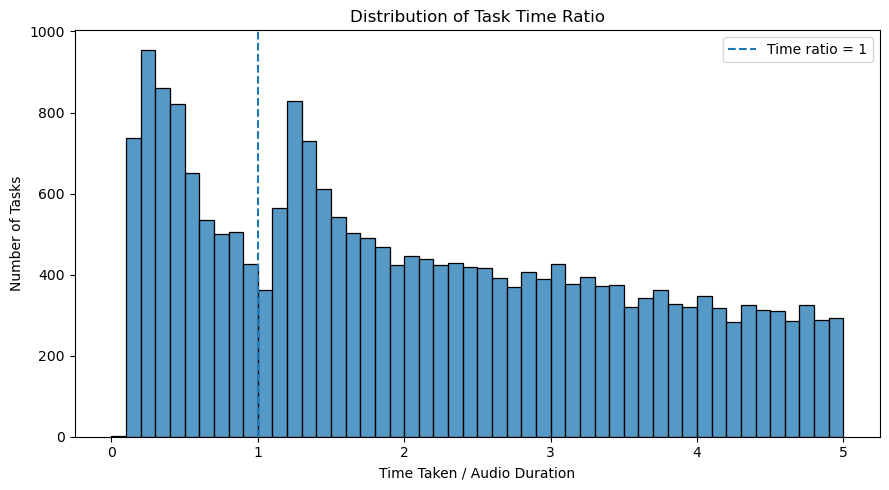

In [43]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=analysis_df[analysis_df["Time_ratio"] <= 5],
    x="Time_ratio",
    bins=50
)

plt.axvline(
    1,
    linestyle="--",
    label="Time ratio = 1"
)

plt.title("Distribution of Task Time Ratio")
plt.xlabel("Time Taken / Audio Duration")
plt.ylabel("Number of Tasks")
plt.legend()
plt.tight_layout()

plt.savefig("time_ratio_distribution.png", dpi=300, bbox_inches="tight")